# 75 · DDPM math, checked numerically: forward process, closed form, noise schedules

In [1]:
import numpy as np, torch, matplotlib.pyplot as plt

def linear_schedule(T, b0=1e-4, b1=0.02):
    return torch.linspace(b0, b1, T)

def cosine_schedule(T, s=0.008):
    t = torch.linspace(0, T, T + 1) / T
    ab = torch.cos((t + s) / (1 + s) * np.pi / 2) ** 2
    ab = ab / ab[0]
    return (1 - ab[1:] / ab[:-1]).clamp(max=0.999)

def two_moons(n):
    t = torch.rand(n) * np.pi
    a = torch.stack([torch.cos(t), torch.sin(t)], 1); b = torch.stack([1 - torch.cos(t), 0.5 - torch.sin(t)], 1)
    x = torch.cat([a[: n // 2], b[n // 2:]]) + 0.05 * torch.randn(n, 2)
    return (x - x.mean(0)) / x.std(0)

In [2]:
T = 1000
beta = linear_schedule(T); alpha = 1 - beta; abar = torch.cumprod(alpha, 0)
x0 = two_moons(4000)
torch.manual_seed(0)
x = x0.clone()
for t in range(500):
    x = alpha[t].sqrt() * x + beta[t].sqrt() * torch.randn_like(x)
closed = abar[499].sqrt() * x0 + (1 - abar[499]).sqrt() * torch.randn_like(x0)
print(f"after 500 iterative steps:  mean {x.mean(0).numpy().round(3)}  var {x.var(0).numpy().round(3)}")
print(f"closed form q(x_500|x_0):   mean {closed.mean(0).numpy().round(3)}  var {closed.var(0).numpy().round(3)}")
print(f"theory: var = ᾱ·var(x0) + (1-ᾱ) = {(abar[499] * x0.var(0) + 1 - abar[499]).numpy().round(3)}")

after 500 iterative steps:  mean [-0.015  0.022]  var [1.003 1.003]
closed form q(x_500|x_0):   mean [0.019 0.014]  var [1.022 0.963]
theory: var = ᾱ·var(x0) + (1-ᾱ) = [1. 1.]


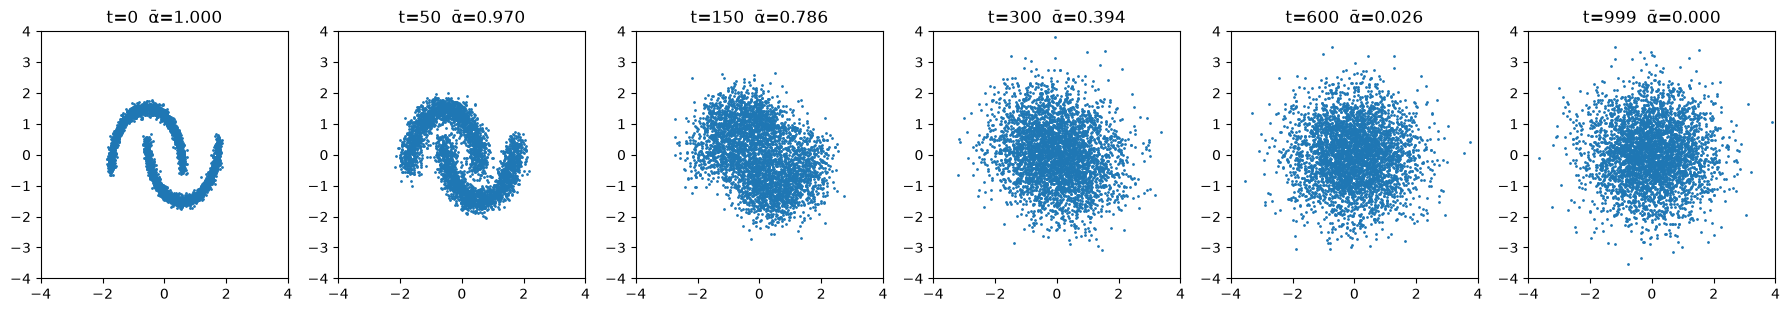

In [3]:
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
for ax, t in zip(axes, [0, 50, 150, 300, 600, 999]):
    xt = abar[t].sqrt() * x0 + (1 - abar[t]).sqrt() * torch.randn_like(x0) if t else x0
    ax.scatter(*xt.T, s=1); ax.set_title(f"t={t}  ᾱ={abar[t]:.3f}"); ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

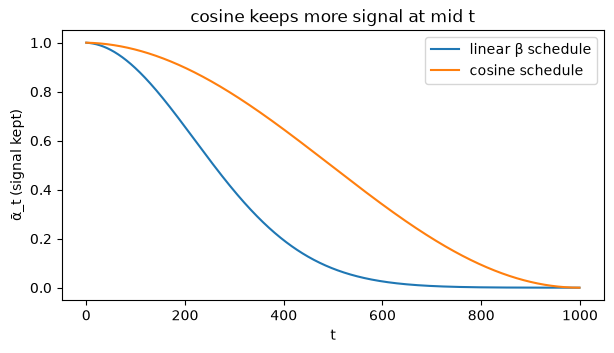

signal-to-noise ratio ᾱ/(1-ᾱ) at t=0: 9997, t=T/2: 0.084, t=T: 4.0e-05


In [4]:
plt.figure(figsize=(7, 3.5))
plt.plot(abar, label="linear β schedule"); plt.plot(torch.cumprod(1 - cosine_schedule(T), 0), label="cosine schedule")
plt.xlabel("t"); plt.ylabel("ᾱ_t (signal kept)"); plt.legend(); plt.title("cosine keeps more signal at mid t"); plt.show()
snr = abar / (1 - abar)
print(f"signal-to-noise ratio ᾱ/(1-ᾱ) at t=0: {snr[0]:.0f}, t=T/2: {snr[T // 2]:.3f}, t=T: {snr[-1]:.1e}")

In [5]:
t = 300
eps = torch.randn_like(x0)
xt = abar[t].sqrt() * x0 + (1 - abar[t]).sqrt() * eps
x0_hat = (xt - (1 - abar[t]).sqrt() * eps) / abar[t].sqrt()
print("ε-prediction ⇔ x0-prediction: recovering x0 from (x_t, true ε) exact:", torch.allclose(x0_hat, x0, atol=1e-5))
mu_post = (abar[t - 1].sqrt() * beta[t] / (1 - abar[t])) * x0 + (alpha[t].sqrt() * (1 - abar[t - 1]) / (1 - abar[t])) * xt
mu_eps = (xt - beta[t] / (1 - abar[t]).sqrt() * eps) / alpha[t].sqrt()
print("posterior mean μ̃(x_t, x_0) == ε-parameterized mean (used by the sampler):", torch.allclose(mu_post, mu_eps, atol=1e-5))

ε-prediction ⇔ x0-prediction: recovering x0 from (x_t, true ε) exact: True
posterior mean μ̃(x_t, x_0) == ε-parameterized mean (used by the sampler): True
